In [ ]:
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.table import Table
import os


# Processing the most recent dataset
path = '../data/raw/Multiwave_UMAP_6_26_26.csv'
df = pd.read_csv(path)

df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
df = df.set_index('name')
df = df.rename({'IR_agn': 'ir_agn'}, axis=1)



display(df.shape)


new_col = ['non_agn', 'zErr_normgal', 'z_code_normgal', 'opt_r', 'r_code_normgal', 'opt_g', 'g_code_normgal', 'CSC_b_lum']
display(df[new_col].describe())


# Treating ' ' as NaN
object_cols = df.select_dtypes(include='object').columns

df[object_cols] = df[object_cols].astype('string').apply(lambda col: col.str.strip())
df[object_cols] = df[object_cols].replace("", np.nan)



# List of columns by dtype
for i in df.dtypes.unique():
    print(f'Columns with {i} dtype:', df.select_dtypes(include=i).columns.tolist())

# Missing value proportion DataFrame
missing = pd.DataFrame({
    'NaN perc': (df.isna().sum() / df.shape[0] * 100).round(2), 
    'missing cnt': df.isna().sum(), 
    'non-missing cnt': df.notna().sum(),
    }).sort_values('NaN perc', ascending=False)

for i in range(0, 100, 25):
    print(f'Columns with NaN values percentage between {i} and {i + 25}: ', end="") 
    print(missing[(missing['NaN perc'] >= i) & 
          (missing['NaN perc'] < i + 25)].shape[0])

missing

C:\Users\I\AppData\Local\Temp\ipykernel_33436\1392368616.py:10: DtypeWarning: Columns (0: conf_flag, 1: extent_flag, 2: PS21P_objID, 3: LEG21P_OBJID, 4: SDSS_CLASS, 5: SDSS_SUBCLASS, 6: AGNDB_spec_class, 7: AGNDB_gen_class, 8: AGNDB_SED_class, 9: AGNDB_xray_class, 10: AGNDB_image_class, 11: AGNDB_best_class, 12: xray_agn, 13: optical_agn, 14: IR_agn, 15: z_code_normgal, 16: r_code_normgal, 17: g_code_normgal) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


(170196, 170)

,zErr_normgal,opt_r,opt_g,CSC_b_lum
count,3639.000000,3639.000000,3639.000000,2.393000e+04
mean,0.050401,19.361375,-20.247647,1.142781e+45
std,0.046660,1.877435,199.423351,6.133754e+46
min,0.000004,12.206410,-999.000000,0.000000e+00
25%,0.014512,18.230600,18.871265,2.327897e+43
50%,0.040825,19.676800,20.618210,1.767983e+44
75%,0.073838,20.703030,21.708835,5.352426e+44
max,0.354680,23.115680,26.221333,9.439978e+48


C:\Users\I\AppData\Local\Temp\ipykernel_33436\1392368616.py:26: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include='object').columns


Columns with float64 dtype: ['ra', 'dec', 'gal_l', 'gal_b', 'err_ellipse_r0', 'err_ellipse_r1', 'err_ellipse_ang', 'significance', 'flux_aper_b', 'flux_aper_lolim_b', 'flux_aper_hilim_b', 'flux_aper_h', 'flux_aper_lolim_h', 'flux_aper_hilim_h', 'flux_aper_m', 'flux_aper_lolim_m', 'flux_aper_hilim_m', 'flux_aper_s', 'flux_aper_lolim_s', 'flux_aper_hilim_s', 'flux_aper_u', 'flux_aper_lolim_u', 'flux_aper_hilim_u', 'flux_aper_w', 'flux_aper_lolim_w', 'flux_aper_hilim_w', 'hard_hm', 'hard_hm_lolim', 'hard_hm_hilim', 'var_inter_hard_prob_hm', 'var_inter_hard_sigma_hm', 'hard_hs', 'hard_hs_lolim', 'hard_hs_hilim', 'var_inter_hard_prob_hs', 'var_inter_hard_sigma_hs', 'hard_ms', 'hard_ms_lolim', 'hard_ms_hilim', 'var_inter_hard_prob_ms', 'var_inter_hard_sigma_ms', 'var_intra_index_b', 'var_intra_index_h', 'var_intra_index_m', 'var_intra_index_s', 'var_intra_index_u', 'var_intra_index_w', 'var_inter_index_b', 'var_inter_index_h', 'var_inter_index_m', 'var_inter_index_s', 'var_inter_index_u', 'v

,NaN perc,missing cnt,non-missing cnt
AGNDB_e_phot_Z,100.00,170196,0
AGNDB_rf20,100.00,170196,0
AGNDB_e_Z,100.00,170196,0
AGNDB_rf6,99.99,170180,16
AGNDB_image_class,99.95,170119,77
...,...,...,...
likelihood_class,0.00,0,170196
dec,0.00,0,170196
ra,0.00,0,170196
significance,0.00,0,170196


In [2]:
# Statistical info about NaN values inside rows
missing_rows = df.isna().sum(axis=1)/df.shape[1] * 100
display(missing_rows.describe())


# Distribution of NaN percentages inside rows
print('Missing row distribution:')

for i in range(0, 100, 10):
    row_cnt = ((missing_rows >= i) & (missing_rows < i + 10)).sum()
    perc = row_cnt / df.shape[0] * 100
    print(f'Percentage of rows with missing values between {i} and {i + 10}: ', round(perc, 5))

count    170196.000000
mean         64.908092
std          13.439520
min          10.588235
25%          60.588235
50%          68.235294
75%          72.941176
max          91.176471
dtype: float64

Missing row distribution:
Percentage of rows with missing values between 0 and 10:  0.0
Percentage of rows with missing values between 10 and 20:  0.6469
Percentage of rows with missing values between 20 and 30:  2.85142
Percentage of rows with missing values between 30 and 40:  4.40316
Percentage of rows with missing values between 40 and 50:  3.79739
Percentage of rows with missing values between 50 and 60:  10.55665
Percentage of rows with missing values between 60 and 70:  33.90503
Percentage of rows with missing values between 70 and 80:  39.70657
Percentage of rows with missing values between 80 and 90:  4.03946
Percentage of rows with missing values between 90 and 100:  0.09342


In [3]:
agn_cols = ["xray_agn", "optical_agn", "ir_agn"]

for col in agn_cols:
    if col in df.columns:
        print("\n")
        print(df[col].value_counts(dropna=False))

"""
for col in agn_cols:
    if col not in df.columns:
        print(f"Warning: {col} not found")
"""

df["agn_class"] = (
    df["xray_agn"].fillna(False).astype(bool) |
    df["optical_agn"].fillna(False).astype(bool) |
    df["ir_agn"].fillna(False).astype(bool)
)

print("\n", df["agn_class"].value_counts(dropna=False))



xray_agn
<NA>    149033
True     21163
Name: count, dtype: int64[pyarrow]


optical_agn
<NA>    156705
True     13491
Name: count, dtype: int64[pyarrow]


ir_agn
<NA>    162275
True      7921
Name: count, dtype: int64[pyarrow]

 agn_class
False    148574
True      21622
Name: count, dtype: int64


C:\Users\I\AppData\Local\Temp\ipykernel_33436\1179581511.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["agn_class"] = (


In [4]:
exclude_cols = [
    "name",
    "col1",
    "ra",
    "dec",
    "gal_l",
    "gal_b",
    
    "xray_agn",
    "optical_agn",
    "ir_agn",
    "agn_class",
    
    "label3_class",
    "non_agn",
    
    "likelihood_class",
    "SDSS_CLASS",
    "SDSS_SUBCLASS",
    "2MASS21P_designation"
]

exclude_cols = [c for c in exclude_cols if c in df.columns]

X = df.drop(columns=exclude_cols, errors="ignore")
X = X.select_dtypes(include=[np.number]).copy()

print(X.shape)
display(X.head())

(170196, 142)


,err_ellipse_r0,err_ellipse_r1,err_ellipse_ang,significance,flux_aper_b,flux_aper_lolim_b,flux_aper_hilim_b,flux_aper_h,flux_aper_lolim_h,flux_aper_hilim_h,...,AGNDB_e_best_Z,AGNDB_f_best_Z,AGNDB_rf5,AGNDB_rf6,AGNDB_rf20,zErr_normgal,opt_r,opt_g,Rec_Z,CSC_b_lum
name,,,,,,,,,,,,,,,,,,,,,
2CXO_J122734.8+752428,0.448858,0.401369,117.360884,3.0,0.0,0.0,2.343371e-15,0.0,0.0,2.265900e-15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2CXO_J015849.8-341338,0.871104,0.505601,92.776679,3.0,0.0,0.0,4.825130e-15,0.0,0.0,4.991575e-15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2CXO_J233119.3+000805,1.618349,0.757823,42.646731,3.0,0.0,0.0,7.358777e-15,0.0,0.0,8.831036e-15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2CXO_J101059.0-044641,1.245511,0.759778,36.915756,3.0,0.0,0.0,3.917044e-14,0.0,0.0,2.213169e-14,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2CXO_J095515.0+693614,1.884902,1.204696,48.475417,3.0,0.0,0.0,5.025451e-15,0.0,0.0,2.471392e-15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
feature_missing_percent = X.isna().mean() * 100

display(
    feature_missing_percent.sort_values(ascending=False).head(10)
)

max_feature_missing = 90

keep_cols = feature_missing_percent[feature_missing_percent <= max_feature_missing].index
X = X[keep_cols].copy()

print(X.shape)

AGNDB_e_phot_Z       100.000000
AGNDB_rf20           100.000000
AGNDB_e_Z            100.000000
AGNDB_rf6             99.990599
AGNDB_rf5             99.747938
var_inter_index_w     99.339585
flux_aper_lolim_w     99.012903
flux_aper_w           99.012903
flux_aper_hilim_w     99.012903
var_intra_index_w     98.570472
dtype: float64

(170196, 109)


In [6]:
# Special column processing: ['CSC_b_lum']
import numpy as np
import pandas as pd

num = X.select_dtypes(include=[np.number])
summary = pd.DataFrame({
    "dtype": num.dtypes,
    "missing_pct": num.isna().mean() * 100,
    "min": num[num != 0].min(),
    "max": num.max(),
    "max_abs": num.abs().max(),
    "median": num.median(),
    "mean": num.mean(),
    "std": num.std(),
    "nunique": num.nunique()
}).sort_values("max_abs", ascending=False)

display(summary.head(50))


big_cols = summary[summary["max_abs"] > 1e20].index.tolist()
for col in big_cols: 
    X.loc[X[col] <= 0, col] = np.nan
    X[col + "_log10"] = np.log10(X[col])
    X = X.drop(columns=col)

X = X.copy()

,dtype,missing_pct,min,max,max_abs,median,mean,std,nunique
CSC_b_lum,float64,85.939740,2.987907e+29,9.439978e+48,9.439978e+48,1.767983e+44,1.142781e+45,6.133754e+46,23831
GAIA21P_source_id,float64,75.333733,8.311621e+13,6.914022e+18,6.914022e+18,2.976654e+18,3.042475e+18,1.859194e+18,41694
LEG21P_LS_ID,float64,36.325178,3.963293e+16,4.529988e+16,4.529988e+16,4.398136e+16,4.283926e+16,1.913969e+15,106272
SDSS_CALIBFLUX_z,float64,89.205387,-1.205755e+00,4.924928e+05,4.924928e+05,1.004335e+01,1.028574e+02,3.916583e+03,15986
SDSS_CALIBFLUX_i,float64,89.205387,-3.907381e-05,3.890452e+05,3.890452e+05,9.572192e+00,9.968702e+01,3.103214e+03,18156
SDSS_CALIBFLUX_u,float64,89.205387,-1.097633e+00,1.375309e+05,1.375309e+05,2.065274e+00,2.243674e+01,1.154053e+03,13286
SDSS_CALIBFLUX_r,float64,89.205387,-8.530114e-05,1.304969e+05,1.304969e+05,7.661768e+00,5.778603e+01,1.101627e+03,18164
SDSS_CALIBFLUX_g,float64,89.205387,-7.689364e-02,6.480369e+04,6.480369e+04,5.349552e+00,3.301422e+01,6.153951e+02,18163
SDSS_MJD_sdss,float64,89.205387,5.157800e+04,6.012300e+04,6.012300e+04,5.670900e+04,5.674665e+04,2.432181e+03,2097
SDSS_CALIBFLUX_IVAR_u,float64,89.205387,9.002225e-04,8.741356e+03,8.741356e+03,5.040586e+00,8.057471e+00,7.052744e+01,12640


In [12]:
# Imputing and encoding the missing data
from sklearn.impute import SimpleImputer

sample_size = len(df) # we can adjust 

df_sample = df.sample(
    n=min(sample_size, len(df)),
    random_state=42
).sort_index().copy()

X_sample = X.loc[df_sample.index].copy()

print(df_sample.shape)
print(X_sample.shape)


missing_indicators = X_sample.isna().astype("int8")
missing_indicators.columns = [f"{col}_missing" for col in X_sample.columns]

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_sample)


X_umap_input = np.hstack([
    X_imputed,
    missing_indicators.values
]).astype("float32")

print(X_umap_input.shape)

(170196, 171)
(170196, 109)
(170196, 218)


In [13]:
# PCA before UMAP
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


# We can also use RobustScaler (instead of StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_umap_input).astype("float32")

n_pca = min(30, X_scaled.shape[1])

pca = PCA(n_components=n_pca, random_state=42)
X_pca = pca.fit_transform(X_scaled).astype("float32")

print(X_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())

(170196, 30)
Explained variance: 0.82274485


In [14]:
# UMAP
import umap

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="euclidean",
    random_state=42,
    n_jobs=-1,
    low_memory=True
)

embedding = reducer.fit_transform(X_pca)

print(embedding.shape)

umap_df = pd.DataFrame(
    {
        "UMAP1": embedding[:, 0],
        "UMAP2": embedding[:, 1]
    },
    index=df_sample.index
)

umap_df["agn_class"] = df_sample["agn_class"].values
umap_df["NaN_percent"] = df_sample.isna().mean(axis=1).values * 100

display(umap_df.head())

c:\Users\I\miniforge3\envs\quant\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\I\miniforge3\envs\quant\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


(170196, 2)


,UMAP1,UMAP2,agn_class,NaN_percent
name,,,,
2CXO_J000000.0+004331,11.406200,4.635907,False,42.105263
2CXO_J000000.3+321702,0.424054,19.958012,False,71.929825
2CXO_J000000.5-575830,1.410906,12.470657,False,70.175439
2CXO_J000001.5-245151,-3.592925,3.417840,False,77.192982
2CXO_J000001.7+003824,0.783826,20.208946,False,71.345029


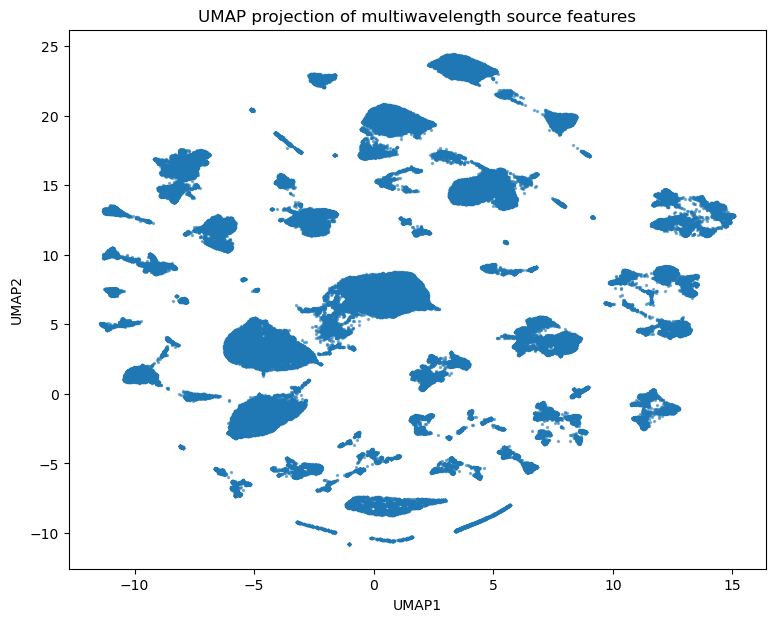

In [16]:
# Plotting UMAP
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.scatter(
    umap_df["UMAP1"],
    umap_df["UMAP2"],
    s=2,
    alpha=0.5
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP projection of multiwavelength source features")
plt.show()

In [1]:
plt.figure(figsize=(9, 7))
mask_agn = umap_df["agn_class"] == True

plt.scatter(
    umap_df.loc[~mask_agn, "UMAP1"],
    umap_df.loc[~mask_agn, "UMAP2"],
    s=2,
    alpha=0.25,
    label="Unconfirmed / unlabeled"
)

plt.scatter(
    umap_df.loc[mask_agn, "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.8,
    label="Confirmed AGN"
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP with confirmed AGN highlighted")
plt.legend(markerscale=4)
plt.show()

NameError: name 'plt' is not defined

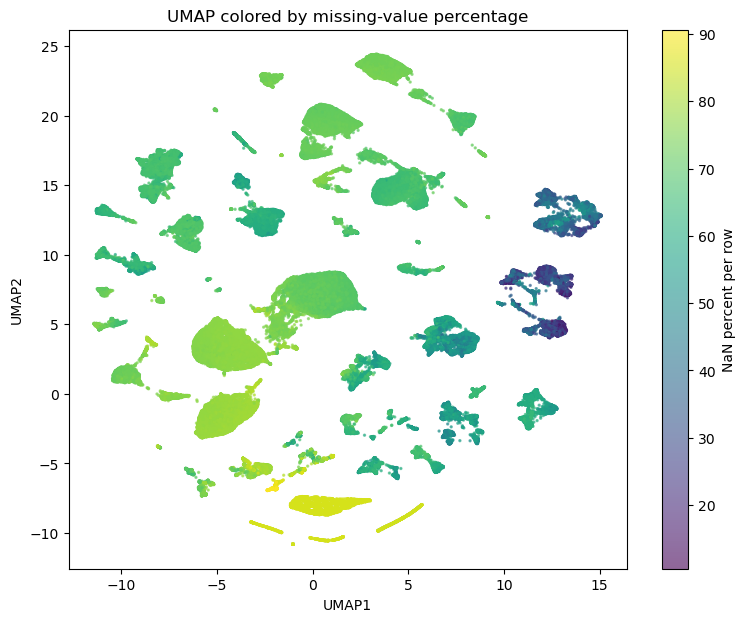

In [18]:
plt.figure(figsize=(9, 7))

plt.scatter(
    umap_df["UMAP1"],
    umap_df["UMAP2"],
    c=umap_df["NaN_percent"],
    s=2,
    alpha=0.6
)

plt.colorbar(label="NaN percent per row")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP colored by missing-value percentage")
plt.show()

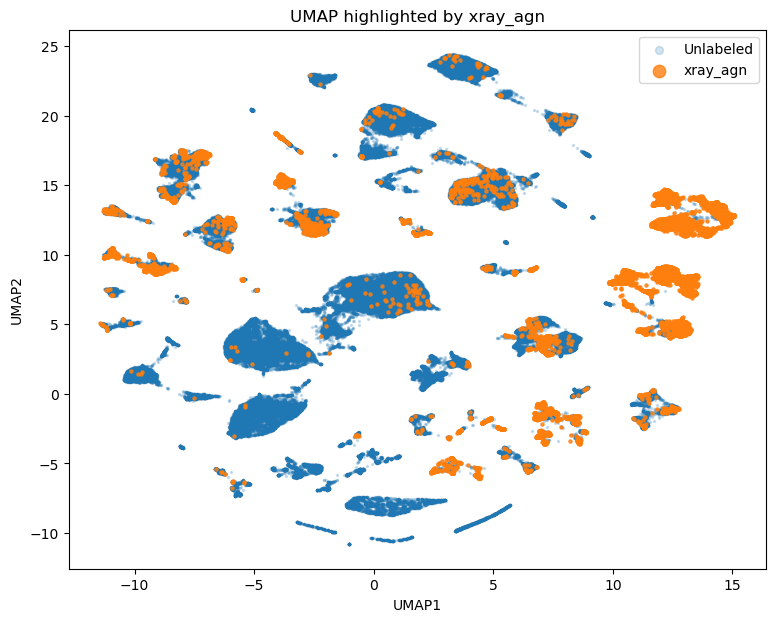

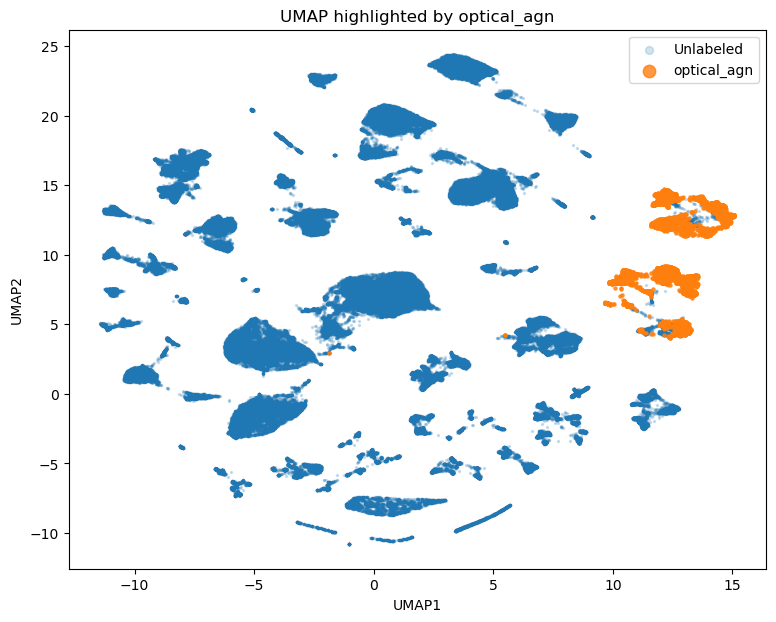

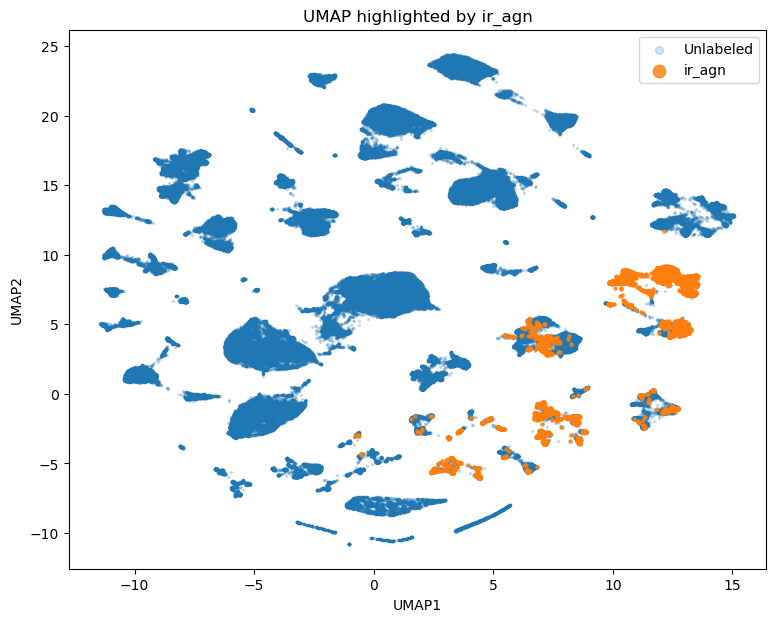

In [19]:
for label_col in ["xray_agn", "optical_agn", "ir_agn"]:
    if label_col in df_sample.columns:
        label_values = df_sample[label_col].fillna(False).astype(bool)
        
        plt.figure(figsize=(9, 7))
        
        plt.scatter(
            umap_df.loc[~label_values, "UMAP1"],
            umap_df.loc[~label_values, "UMAP2"],
            s=2,
            alpha=0.2,
            label="Unlabeled"
        )
        
        plt.scatter(
            umap_df.loc[label_values, "UMAP1"],
            umap_df.loc[label_values, "UMAP2"],
            s=5,
            alpha=0.8,
            label=label_col
        )
        
        plt.xlabel("UMAP1")
        plt.ylabel("UMAP2")
        plt.title(f"UMAP highlighted by {label_col}")
        plt.legend(markerscale=4)
        plt.show()